# NB-12 — Correção de redações por LLMs com a matriz do ENEM (Cap. 5)

Avalia se um LLM pode corrigir a redação a partir da transcrição do HTR, usando a matriz de referência do ENEM (cinco competências, níveis 0–200; cartilha do Inep 2025).

- **E1 — robustez:** a página **1680-069** corrigida a partir do gabarito e das transcrições dos motores do NB-05 (imagem original), por quatro juízes, três repetições cada. Pergunta: quanto cada competência cai com os erros de transcrição? Hipótese: a C1 (norma escrita) é a mais frágil, porque o juiz não distingue erro do participante de erro do reconhecimento.
- **Desconto na C1:** ΔC1 ≈ β·WER, com β estimado por juiz sem o motor avaliado (deixa-um-fora); a C1 corrigida é C1 − β·WER, arredondada ao nível mais próximo.
- **E2 — concordância:** 20 redações do conjunto de **teste** do BRESSAY com o mesmo tema (sorteio com semente 0), corrigidas pelo gabarito. Sem notas humanas no BRESSAY: mede consistência entre juízes, não acerto. Métricas: taxa de discrepância pela regra do ENEM e QWK por competência.
- **Execução:** `nb12_rodar.py` (fora do Jupyter, porque a OpenRouter cobra), que grava um JSON por correção em `saidas/NB-12/cache/`. Este notebook só lê o cache.
- **Limitações:** o juiz não recebe os textos motivadores da prova; o tema é o da redação, e os níveis da C2/C3 que citam os textos motivadores ficam a critério do juiz.

In [1]:
# Parâmetros
import sys
sys.path[:0] = ['lib', '..']
from pathlib import Path
SAIDA = Path('saidas/NB-12')
SEED = 0  # o sorteio do E2 é feito no nb12_rodar.py com esta semente

In [2]:
import json
from datetime import datetime
import pandas as pd
from IPython.display import Image, display
from correcao_enem import JUIZES, carregar, TEMA
import correcao_saidas as S

e1 = json.loads((SAIDA / 'itens_e1.json').read_text())
e2 = json.loads((SAIDA / 'itens_e2.json').read_text())
d1 = S.tabela_registros(carregar(e1, SAIDA, reps=3))
d2 = S.tabela_registros(carregar(e2, SAIDA, reps=1))
print('tema:', TEMA)
print(f'E1: {len(e1)} transcrições, {len(d1)} correções (esperado {len(e1) * len(JUIZES) * 3})')
print(f'E2: {len(e2)} redações, {len(d2)} correções (esperado {len(e2) * len(JUIZES)})')
custo = pd.concat([d1, d2]).custo_usd.sum()
print(f'custo total das correções: US$ {custo:.2f}')

tema: O estigma associado às doenças mentais na sociedade brasileira
E1: 13 transcrições, 156 correções (esperado 156)
E2: 20 redações, 80 correções (esperado 80)
custo total das correções: US$ 3.29


## E1 — Robustez da nota aos erros de transcrição

In [3]:
g = S.e1_medias(d1)
tab = g.groupby('motor').agg(cer=('cer', 'first'), wer=('wer', 'first'),
                             **{c: (c, 'mean') for c in ['c1', 'c2', 'c3', 'c4', 'c5', 'total']}).sort_values('cer')
tab.round(3)

,cer,wer,c1,c2,c3,c4,c5,total
motor,,,,,,,,
gabarito,0.000,0.000,160.000,166.667,153.333,166.667,180.000,826.667
OpenRouter|anthropic/claude-sonnet-5.5,0.005,0.047,150.000,173.333,153.333,173.333,180.000,830.000
OpenRouter|anthropic/claude-haiku-5.5,0.009,0.052,170.000,180.000,153.333,170.000,180.000,853.333
OpenRouter|z-ai/glm-5.3-flash,0.009,0.047,160.000,166.667,153.333,170.000,180.000,830.000
OpenRouter|openai/gpt-6-luna,0.010,0.052,166.667,166.667,153.333,170.000,180.000,836.667
OpenRouter|google/gemini-2.5-flash,0.011,0.031,160.000,173.333,156.667,170.000,180.000,840.000
OpenRouter|qwen/qwen3-vl-235b-a22b-instruct,0.017,0.060,160.000,163.333,150.000,163.333,180.000,816.667
Ollama|richardyoung/olmocr2:7b-q8,0.018,0.076,160.000,176.667,153.333,166.667,180.000,836.667
OpenRouter|google/gemini-3.8-flash,0.031,0.071,166.667,170.000,153.333,166.667,180.000,836.667


In [4]:
# Variação entre repetições (mesmo juiz, mesmo texto, temperatura 0)
print('desvio-padrão médio entre repetições — C1: {:.1f}; total: {:.1f}'.format(g.dp_c1.mean(), g.dp_total.mean()))
g.pivot_table(index='motor', columns='juiz', values='d_total').round(0)

desvio-padrão médio entre repetições — C1: 1.3; total: 19.7


juiz,anthropic/claude-sonnet-5.5,google/gemini-4-carbon,openai/gpt-6.1-terra,qwen/qwen3-235b-a22b-2507
motor,,,,
EasyOCR,-560.0,-693.0,-413.0,-800.0
Ollama|glm-ocr:q8_0,-360.0,-413.0,-293.0,-147.0
Ollama|richardyoung/olmocr2:7b-q8,13.0,0.0,27.0,0.0
OpenRouter|anthropic/claude-haiku-5.5,0.0,13.0,67.0,27.0
OpenRouter|anthropic/claude-sonnet-5.5,0.0,13.0,0.0,0.0
OpenRouter|google/gemini-2.5-flash,-40.0,0.0,40.0,53.0
OpenRouter|google/gemini-3.8-flash,-40.0,-13.0,67.0,27.0
OpenRouter|mistralai/mistral-small-3.2-24b-instruct,-160.0,-40.0,-53.0,-27.0
OpenRouter|openai/gpt-6-luna,-27.0,0.0,27.0,40.0


In [5]:
# Spearman entre o CER e a variação de cada competência (sem as transcrições com CER > 100%)
S.e1_correlacoes(g).round(2)

,juiz,c1,c2,c3,c4,c5
0,anthropic/claude-sonnet-5.5,-0.79,-0.74,-0.59,-0.78,-0.77
1,google/gemini-4-carbon,-0.61,-0.50,-0.50,-0.43,-0.50
2,openai/gpt-6.1-terra,-0.53,-0.55,-0.67,-0.70,-0.67
3,qwen/qwen3-235b-a22b-2507,-0.67,-0.52,-0.52,-0.63,-0.78


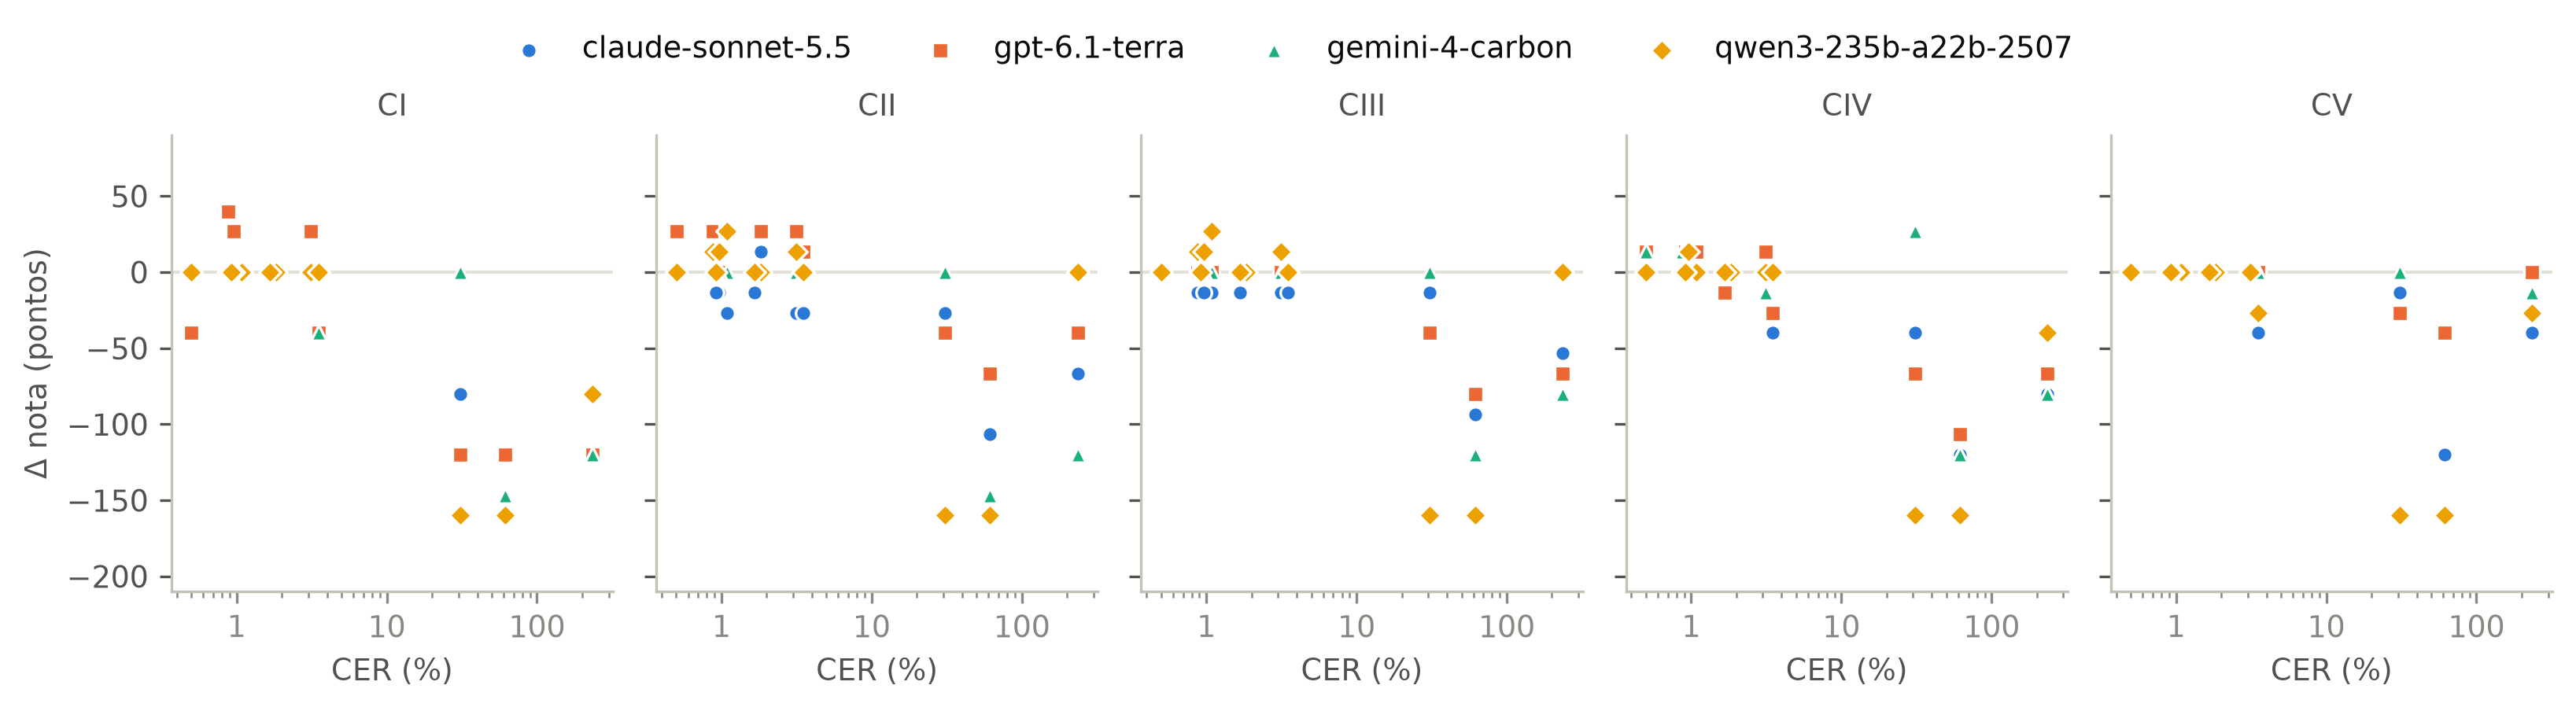

In [6]:
S.figura_e1(g, SAIDA / 'fig_e1_delta_competencias.png')
display(Image(SAIDA / 'fig_e1_delta_competencias.png', width=900))

### Desconto na C1 pelo WER

In [7]:
desc = S.e1_desconto(g)
print(desc.groupby('juiz').beta_loo.mean().round(1).rename('β médio (pontos por WER=1)'))
print()
print('erro absoluto médio da C1 em relação ao gabarito (todas as transcrições com CER <= 100%):')
print(desc.groupby('juiz')[['erro_antes', 'erro_depois']].mean().round(1))
bons = desc[desc.cer < 0.05]
print()
print('só transcrições boas (CER < 5%):')
print(bons.groupby('juiz')[['erro_antes', 'erro_depois']].mean().round(1))

juiz
anthropic/claude-sonnet-5.5   -114.6
google/gemini-4-carbon         -89.6
openai/gpt-6.1-terra          -132.5
qwen/qwen3-235b-a22b-2507     -176.3
Name: β médio (pontos por WER=1), dtype: float64

erro absoluto médio da C1 em relação ao gabarito (todas as transcrições com CER <= 100%):
                             erro_antes  erro_depois
juiz                                                
anthropic/claude-sonnet-5.5        21.8          3.6
google/gemini-4-carbon             17.0         21.8
openai/gpt-6.1-terra               37.6         25.5
qwen/qwen3-235b-a22b-2507          29.1          7.3

só transcrições boas (CER < 5%):
                             erro_antes  erro_depois
juiz                                                
anthropic/claude-sonnet-5.5         4.4          4.4
google/gemini-4-carbon              4.4          4.4
openai/gpt-6.1-terra               19.3         22.2
qwen/qwen3-235b-a22b-2507           0.0          0.0


## E2 — Concordância entre juízes

In [8]:
print(S.e2_por_juiz(d2).round(0).to_string(index=False))
pares = S.e2_pares(d2)
pares.round(2)

                       juiz    c1    c2    c3    c4    c5  total
anthropic/claude-sonnet-5.5 128.0 138.0 138.0 142.0 144.0  690.0
       openai/gpt-6.1-terra 116.0 168.0 148.0 178.0 192.0  802.0
     google/gemini-4-carbon 126.0 188.0 154.0 156.0 192.0  816.0
  qwen/qwen3-235b-a22b-2507 158.0 170.0 170.0 164.0 154.0  816.0


,par,n,discrepancia,dif_total,qwk_c1,qwk_c2,qwk_c3,qwk_c4,qwk_c5
0,claude-sonnet-5.5 × gpt-6.1-terra,20,0.75,136.0,0.68,0.25,0.40,0.29,-0.07
1,claude-sonnet-5.5 × gemini-4-carbon,20,0.50,134.0,0.81,0.03,0.21,0.41,-0.03
2,claude-sonnet-5.5 × qwen3-235b-a22b-2507,20,0.70,130.0,0.12,0.26,0.26,0.23,0.34
3,gpt-6.1-terra × gemini-4-carbon,20,0.20,70.0,0.64,0.23,0.36,0.35,-0.08
4,gpt-6.1-terra × qwen3-235b-a22b-2507,20,0.30,86.0,0.05,0.10,0.23,0.20,-0.03
5,gemini-4-carbon × qwen3-235b-a22b-2507,20,0.10,64.0,0.10,0.07,0.13,0.23,0.03


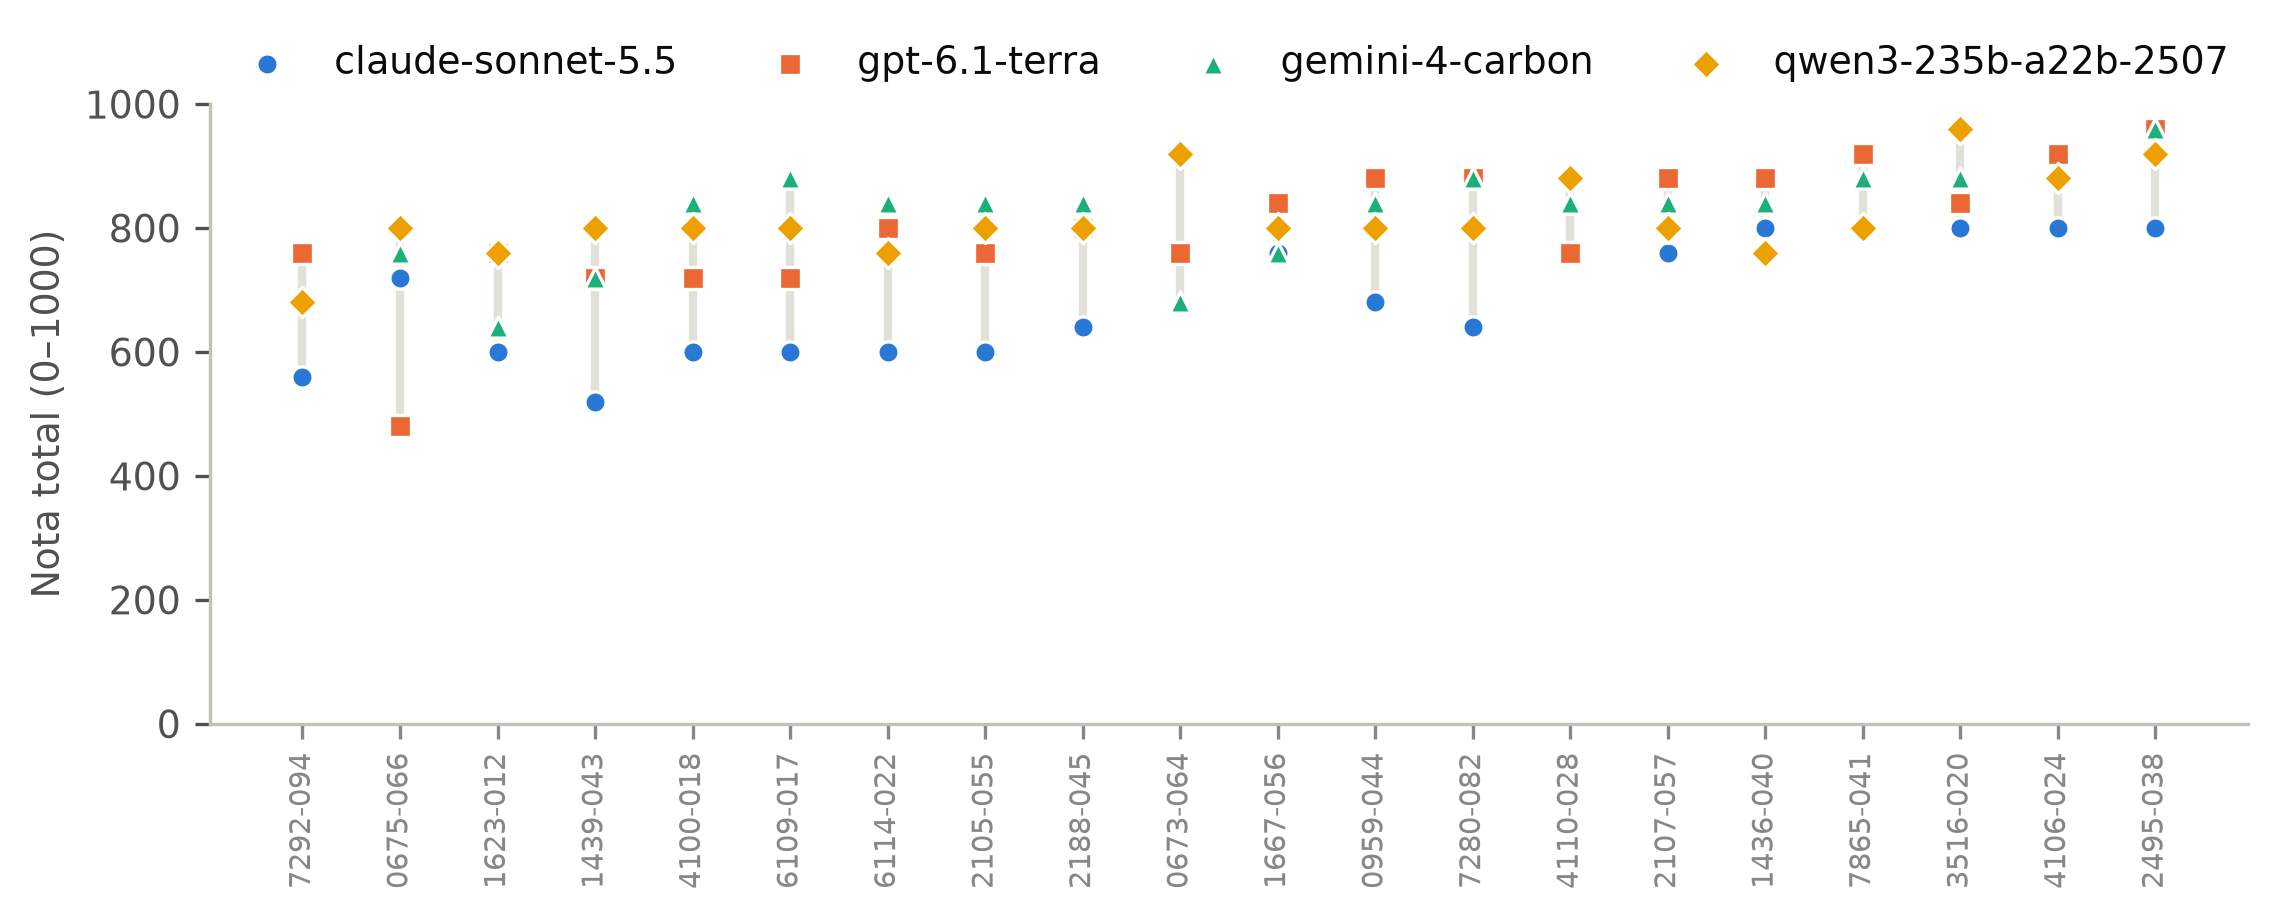

In [9]:
S.figura_e2(d2, SAIDA / 'fig_e2_notas_por_redacao.png')
display(Image(SAIDA / 'fig_e2_notas_por_redacao.png', width=800))

## Saídas para o texto

In [10]:
(SAIDA / 'tabela_e1.tex').write_text(S.tabela_e1(g))
(SAIDA / 'tabela_e2.tex').write_text(S.tabela_e2(pares))
d1.drop(columns=['resposta']).to_csv(SAIDA / 'correcoes_e1.csv', index=False)
d2.drop(columns=['resposta']).to_csv(SAIDA / 'correcoes_e2.csv', index=False)
manifest = {'notebook': 'NB-12', 'data': datetime.now().isoformat(timespec='seconds'), 'tema': TEMA,
            'juizes': JUIZES, 'e1_itens': [i['id'] for i in e1], 'e2_paginas': [i['id'] for i in e2],
            'reps_e1': 3, 'temperature': 0.0, 'custo_usd': round(float(custo), 4)}
(SAIDA / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=1))
sorted(p.name for p in SAIDA.iterdir() if p.is_file())

['correcoes_e1.csv',
 'correcoes_e2.csv',
 'fig_e1_delta_competencias.png',
 'fig_e2_notas_por_redacao.png',
 'itens_e1.json',
 'itens_e2.json',
 'manifest.json',
 'tabela_e1.tex',
 'tabela_e2.tex']